# Case Study 1: Healthcare & Biology in the Cloud
### Local demonstration notebook | DNA sequence alignment · Protein lattice model · ECG analysis

**Purpose.** Demonstrate the three small computational examples described in the accompanying case study report. This notebook runs in Google Colab using Python; it does **not** connect to AWS, Azure, or another cloud service. Colab is only the notebook execution environment.

**Data and limitations:** sequences are toy examples, the protein model is a simplified 2D hydrophobic–polar (HP) lattice, and the ECG is synthetic. Results are educational demonstrations, not clinical findings or cloud performance benchmarks.

**How to run:** choose **Runtime → Run all**. The notebook is organized into independent sections so each result can be explained during a presentation.

## 1. Setup and reproducibility
The examples use NumPy, SciPy, pandas, and Matplotlib. A fixed random seed is used for the synthetic ECG so results are reproducible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
from collections import Counter

SEED = 7
np.set_printoptions(suppress=True)
print("Setup complete")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Setup complete
NumPy: 2.3.5
Pandas: 2.2.3


## 2. Gene sequencing concept: global DNA sequence alignment

The Needleman–Wunsch dynamic-programming algorithm aligns two complete sequences. A match receives +1, a mismatch −1, and a gap −2. Gaps can reveal candidate insertions/deletions in this toy example; real genomic pipelines require read quality checks and further validation.

In [2]:
def needleman_wunsch(a, b, match=1, mismatch=-1, gap=-2):
    """Return optimal global-alignment score, aligned sequences, and DP matrix."""
    n, m = len(a), len(b)
    S = np.zeros((n + 1, m + 1), dtype=int)
    S[:, 0] = np.arange(n + 1) * gap
    S[0, :] = np.arange(m + 1) * gap
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            diagonal = S[i-1, j-1] + (match if a[i-1] == b[j-1] else mismatch)
            S[i, j] = max(diagonal, S[i-1, j] + gap, S[i, j-1] + gap)
    i, j, A, B = n, m, [], []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and S[i,j] == S[i-1,j-1] + (match if a[i-1] == b[j-1] else mismatch):
            A.append(a[i-1]); B.append(b[j-1]); i -= 1; j -= 1
        elif i > 0 and S[i,j] == S[i-1,j] + gap:
            A.append(a[i-1]); B.append('-'); i -= 1
        else:
            A.append('-'); B.append(b[j-1]); j -= 1
    return int(S[n,m]), ''.join(reversed(A)), ''.join(reversed(B)), S

reference = "ATGGCGTACGTTAGC"
read =      "ATGGCTACGTTTAGC"
score, aligned_ref, aligned_read, dp_matrix = needleman_wunsch(reference, read)
match_line = ''.join('|' if x == y else ' ' for x, y in zip(aligned_ref, aligned_read))
print("Reference:", reference)
print("Read:     ", read)
print("Alignment score:", score)
print("Ref:      ", aligned_ref)
print("          ", match_line)
print("Read:     ", aligned_read)
print("Alignment columns:", len(aligned_ref))
print("Exact-match columns:", sum(x == y for x, y in zip(aligned_ref, aligned_read)))
assert len(aligned_ref) == len(aligned_read)

Reference: ATGGCGTACGTTAGC
Read:      ATGGCTACGTTTAGC
Alignment score: 10
Ref:       ATGGCGTACG-TTAGC
           ||||| |||| |||||
Read:      ATGGC-TACGTTTAGC
Alignment columns: 16
Exact-match columns: 14


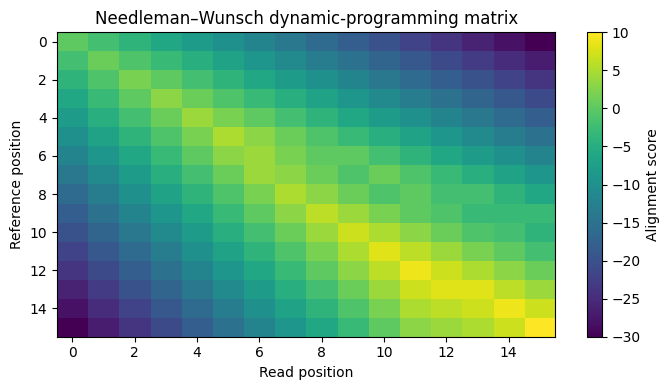

Toy sequence length: 24 bases
GC fraction: 0.542
Four most common 3-mers: [('GCG', 3), ('CGT', 3), ('ATG', 2), ('GTA', 2)]


In [3]:
plt.figure(figsize=(7, 4))
plt.imshow(dp_matrix, aspect='auto', origin='upper')
plt.colorbar(label='Alignment score')
plt.title('Needleman–Wunsch dynamic-programming matrix')
plt.xlabel('Read position')
plt.ylabel('Reference position')
plt.tight_layout()
plt.show()

# Small sequence summary, as in the report
sequence = "ATGGCGTACGTTAGCATGCGCGTA"
gc_fraction = (sequence.count('G') + sequence.count('C')) / len(sequence)
kmer_counts = Counter(sequence[i:i+3] for i in range(len(sequence)-2))
print(f"Toy sequence length: {len(sequence)} bases")
print(f"GC fraction: {gc_fraction:.3f}")
print("Four most common 3-mers:", kmer_counts.most_common(4))

### Interpretation
The dynamic-programming matrix finds a high-scoring alignment while allowing gaps. This demonstrates the *algorithmic workload* that a sequencing pipeline performs. Large-scale real sequencing involves many reads, reference indexes, quality control, variant calling, storage, and secure data handling; those production steps are discussed in the report but are not implemented here.

## 3. Protein folding concept: 2D hydrophobic–polar lattice model

This is **not** AlphaFold and does not predict a real protein's 3D structure. It uses a simplified HP model on a square grid. The chain is a self-avoiding walk (a grid location cannot be reused); each non-neighbouring H–H contact contributes −1 energy. We first count possible conformations for chain lengths 4–16 without storing them all, then score every conformation for the report's 12-residue toy sequence.

In [4]:
DIRECTIONS = ((1,0), (0,1), (-1,0), (0,-1))

def count_walks(n):
    """Count self-avoiding walks with first bond fixed; use little memory."""
    occupied = {(0,0), (1,0)}
    path = [(0,0), (1,0)]
    def visit():
        if len(path) == n:
            return 1
        x, y = path[-1]
        total = 0
        for dx, dy in DIRECTIONS:
            q = (x+dx, y+dy)
            if q not in occupied:
                occupied.add(q); path.append(q)
                total += visit()
                path.pop(); occupied.remove(q)
        return total
    return visit()

lengths = list(range(4, 17))
counts = [count_walks(n) for n in lengths]
counts_df = pd.DataFrame({'Chain length': lengths, 'Conformations': counts})
display(counts_df)
assert counts[-1] == 1604149, "Walk count should match the report's 16-residue count."

,Chain length,Conformations
0,4,9
1,5,25
2,6,71
3,7,195
4,8,543
5,9,1479
6,10,4067
7,11,11025
8,12,30073
9,13,81233


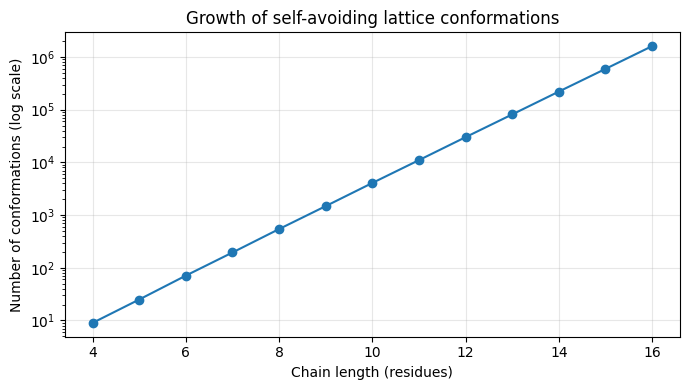

HP sequence: HPHPPHHPHPPH
Conformations scored: 30073
Minimum energy: -5
Number of minimum-energy conformations: 4


In [5]:
plt.figure(figsize=(7, 4))
plt.plot(lengths, counts, marker='o')
plt.yscale('log')
plt.title('Growth of self-avoiding lattice conformations')
plt.xlabel('Chain length (residues)')
plt.ylabel('Number of conformations (log scale)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

HP_SEQUENCE = "HPHPPHHPHPPH"

def enumerate_walks(n):
    """Return all self-avoiding walks for a short chain; first bond fixed."""
    result = []
    path = [(0,0), (1,0)]
    occupied = set(path)
    def visit():
        if len(path) == n:
            result.append(tuple(path)); return
        x, y = path[-1]
        for dx, dy in DIRECTIONS:
            q = (x+dx, y+dy)
            if q not in occupied:
                occupied.add(q); path.append(q)
                visit()
                path.pop(); occupied.remove(q)
    visit()
    return result

def hp_energy(walk, sequence=HP_SEQUENCE):
    position_to_index = {point: i for i, point in enumerate(walk)}
    energy = 0
    for i, (x, y) in enumerate(walk):
        if sequence[i] != 'H':
            continue
        # Check only right/up directions to count each contact once.
        for dx, dy in ((1,0), (0,1)):
            j = position_to_index.get((x+dx, y+dy))
            if j is not None and sequence[j] == 'H' and abs(i-j) > 1:
                energy -= 1
    return energy

walks_12 = enumerate_walks(len(HP_SEQUENCE))
energies = np.array([hp_energy(w) for w in walks_12])
minimum_energy = int(energies.min())
best_walks = [w for w, e in zip(walks_12, energies) if e == minimum_energy]
print("HP sequence:", HP_SEQUENCE)
print("Conformations scored:", len(walks_12))
print("Minimum energy:", minimum_energy)
print("Number of minimum-energy conformations:", len(best_walks))
assert len(walks_12) == 30073 and minimum_energy == -5 and len(best_walks) == 4

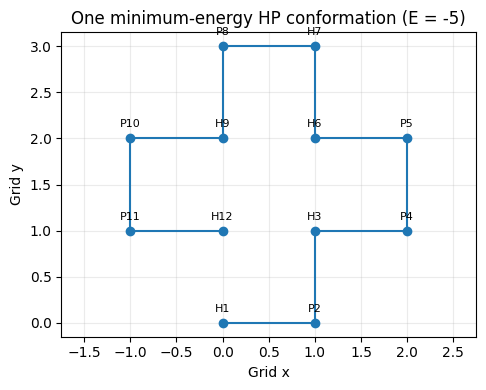

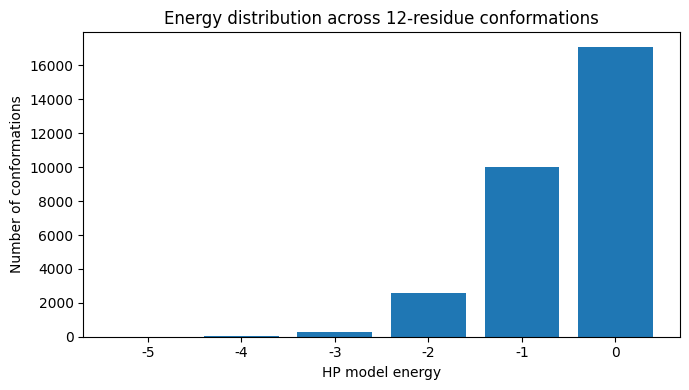

In [6]:
def plot_lattice(walk, title):
    xs = [p[0] for p in walk]; ys = [p[1] for p in walk]
    plt.figure(figsize=(5, 4))
    plt.plot(xs, ys, marker='o')
    for i, (x, y) in enumerate(walk):
        plt.text(x, y + 0.12, f"{HP_SEQUENCE[i]}{i+1}", ha='center', fontsize=8)
    plt.gca().set_aspect('equal', adjustable='datalim')
    plt.grid(True, alpha=0.25)
    plt.title(title)
    plt.xlabel('Grid x'); plt.ylabel('Grid y')
    plt.tight_layout(); plt.show()

plot_lattice(best_walks[0], f'One minimum-energy HP conformation (E = {minimum_energy})')
energy_counts = pd.Series(energies).value_counts().sort_index()
plt.figure(figsize=(7, 4))
plt.bar(energy_counts.index.astype(str), energy_counts.values)
plt.title('Energy distribution across 12-residue conformations')
plt.xlabel('HP model energy'); plt.ylabel('Number of conformations')
plt.tight_layout(); plt.show()

### Interpretation
The number of possible conformations rises rapidly with chain length, illustrating why exhaustive search becomes impractical. The minimum-energy result is specific to this simplified 2D model and short sequence. The report's discussion of GPU-based cloud resources and modern protein-structure predictors is contextual; this notebook does not run a deep-learning folding model.

## 4. ECG concept: filtering and R-peak detection on a synthetic signal

We generate a 10-second ECG-like signal at 360 Hz from simple Gaussian P, Q, R, S, and T components. We add baseline wander, 50 Hz interference, and Gaussian noise, then apply a 5–15 Hz band-pass filter, derivative-squared energy, moving-window integration, thresholding, and a refractory distance to estimate R peaks.

In [7]:
rng = np.random.default_rng(SEED)
fs, duration = 360, 10
t = np.arange(0, duration, 1/fs)
rr_intervals = 0.825 + 0.02 * rng.standard_normal(14)
beat_times = [0.5]
while beat_times[-1] < duration - 0.6:
    beat_times.append(beat_times[-1] + rr_intervals[len(beat_times) % len(rr_intervals)])
beat_times = np.array([b for b in beat_times if b < duration - 0.4])

def gaussian_component(t, mu, sigma, amplitude):
    return amplitude * np.exp(-((t-mu)**2)/(2*sigma*sigma))

clean_ecg = np.zeros_like(t)
for beat in beat_times:
    clean_ecg += gaussian_component(t, beat-0.20, 0.025, 0.15)
    clean_ecg += gaussian_component(t, beat-0.04, 0.010, -0.12)
    clean_ecg += gaussian_component(t, beat,       0.011, 1.00)
    clean_ecg += gaussian_component(t, beat+0.04,  0.012, -0.22)
    clean_ecg += gaussian_component(t, beat+0.25,  0.050, 0.30)

noisy_ecg = (clean_ecg + 0.25*np.sin(2*np.pi*0.3*t)
             + 0.05*np.sin(2*np.pi*50*t)
             + 0.03*rng.standard_normal(len(t)))
b, a = butter(2, [5/(fs/2), 15/(fs/2)], btype='band')
filtered_ecg = filtfilt(b, a, noisy_ecg)
squared_derivative = np.gradient(filtered_ecg)**2
window = max(1, int(0.15*fs))
integrated_energy = np.convolve(squared_derivative, np.ones(window)/window, mode='same')
peaks, _ = find_peaks(integrated_energy, height=0.35*integrated_energy.max(), distance=int(0.25*fs))
r_peaks = []
for p in peaks:
    lo, hi = max(0, p-int(0.1*fs)), min(len(filtered_ecg), p+int(0.1*fs))
    r_peaks.append(lo + int(np.argmax(filtered_ecg[lo:hi])))
r_peaks = np.array(r_peaks, dtype=int)
true_indices = np.array([int(round(bt*fs)) for bt in beat_times])

def score_detections(detected, truth, tolerance_samples):
    matched = set()
    for p in detected:
        distances = np.abs(truth-p)
        if len(distances) == 0: continue
        k = int(distances.argmin())
        if distances[k] <= tolerance_samples and k not in matched:
            matched.add(k)
    tp = len(matched); fp = len(detected)-tp; fn = len(truth)-tp
    return tp, fp, fn

tp, fp, fn = score_detections(r_peaks, true_indices, int(0.05*fs))
sensitivity = tp/(tp+fn) if tp+fn else 0.0
precision = tp/(tp+fp) if tp+fp else 0.0
hr_detected = 60 / np.mean(np.diff(r_peaks)/fs) if len(r_peaks)>1 else np.nan
hr_generated = 60 / np.mean(np.diff(true_indices)/fs) if len(true_indices)>1 else np.nan
metrics = pd.DataFrame([
    ('Generated beats', len(true_indices)), ('Detected beats', len(r_peaks)),
    ('True positives', tp), ('False positives', fp), ('False negatives', fn),
    ('Sensitivity', round(sensitivity, 3)), ('Precision', round(precision, 3)),
    ('Mean heart rate from detections (bpm)', round(hr_detected, 2)),
    ('Mean generated heart rate (bpm)', round(hr_generated, 2))
], columns=['Metric','Value'])
display(metrics)

,Metric,Value
0,Generated beats,12.00
1,Detected beats,12.00
2,True positives,12.00
3,False positives,0.00
4,False negatives,0.00
5,Sensitivity,1.00
6,Precision,1.00
7,Mean heart rate from detections (bpm),72.93
8,Mean generated heart rate (bpm),72.91


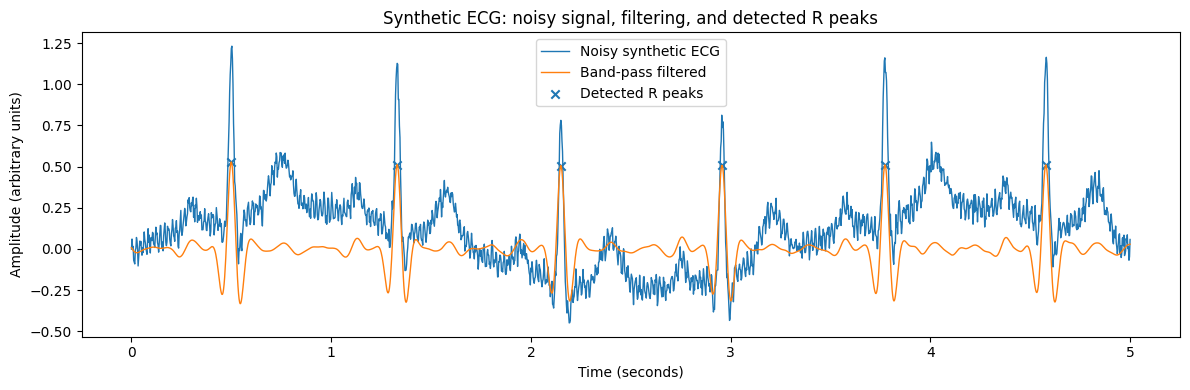

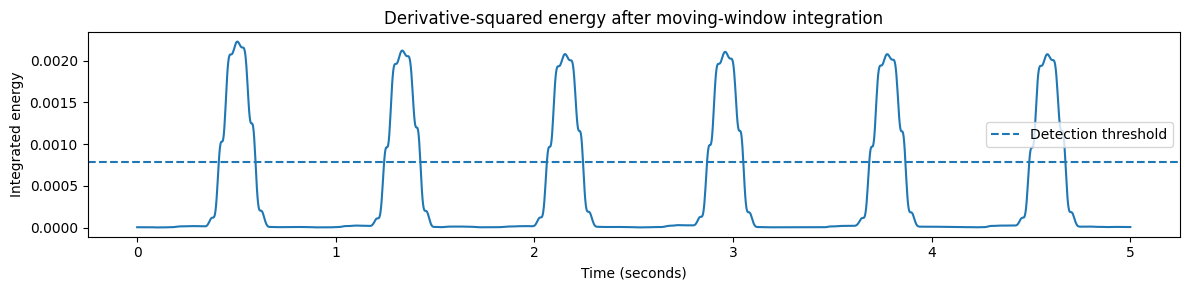

In [8]:
show = t <= 5
plt.figure(figsize=(12, 4))
plt.plot(t[show], noisy_ecg[show], label='Noisy synthetic ECG', linewidth=1)
plt.plot(t[show], filtered_ecg[show], label='Band-pass filtered', linewidth=1)
selected = r_peaks[r_peaks/fs <= 5]
plt.scatter(selected/fs, filtered_ecg[selected], label='Detected R peaks', marker='x')
plt.title('Synthetic ECG: noisy signal, filtering, and detected R peaks')
plt.xlabel('Time (seconds)'); plt.ylabel('Amplitude (arbitrary units)')
plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(12, 3))
plt.plot(t[show], integrated_energy[show])
plt.axhline(0.35*integrated_energy.max(), linestyle='--', label='Detection threshold')
plt.title('Derivative-squared energy after moving-window integration')
plt.xlabel('Time (seconds)'); plt.ylabel('Integrated energy')
plt.legend(); plt.tight_layout(); plt.show()

,Noise std. dev.,Detected,True positives,False positives,False negatives
0,0.1,12,12,0,0
1,0.3,12,12,0,0
2,0.6,9,9,0,3
3,1.0,11,6,5,6


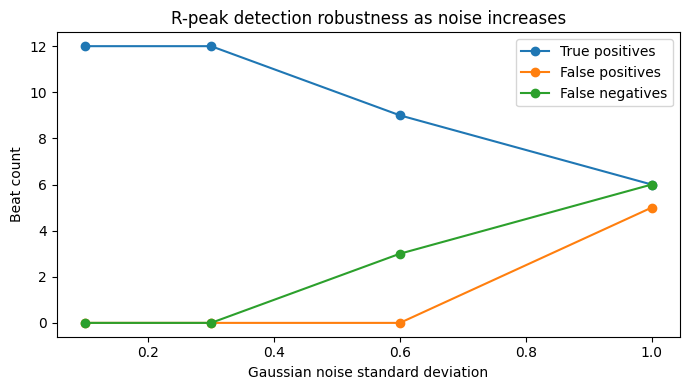

In [9]:
robustness_rows = []
for noise_std in [0.1, 0.3, 0.6, 1.0]:
    noise_rng = np.random.default_rng(1)
    signal = (clean_ecg + 0.25*np.sin(2*np.pi*0.3*t)
              + 0.05*np.sin(2*np.pi*50*t)
              + noise_std*noise_rng.standard_normal(len(t)))
    filtered = filtfilt(b, a, signal)
    energy = np.convolve(np.gradient(filtered)**2, np.ones(window)/window, mode='same')
    pks, _ = find_peaks(energy, height=0.35*energy.max(), distance=int(0.25*fs))
    detected = []
    for p in pks:
        lo, hi = max(0, p-int(0.1*fs)), min(len(filtered), p+int(0.1*fs))
        detected.append(lo + int(np.argmax(filtered[lo:hi])))
    tpos, fpos, fneg = score_detections(np.array(detected), true_indices, int(0.05*fs))
    robustness_rows.append({'Noise std. dev.': noise_std, 'Detected': len(detected),
                            'True positives': tpos, 'False positives': fpos, 'False negatives': fneg})
robustness = pd.DataFrame(robustness_rows)
display(robustness)
plt.figure(figsize=(7, 4))
plt.plot(robustness['Noise std. dev.'], robustness['True positives'], marker='o', label='True positives')
plt.plot(robustness['Noise std. dev.'], robustness['False positives'], marker='o', label='False positives')
plt.plot(robustness['Noise std. dev.'], robustness['False negatives'], marker='o', label='False negatives')
plt.title('R-peak detection robustness as noise increases')
plt.xlabel('Gaussian noise standard deviation'); plt.ylabel('Beat count')
plt.legend(); plt.tight_layout(); plt.show()

### Interpretation and conclusion

- **Sequence alignment:** dynamic programming aligns two short DNA strings and displays a score matrix.
- **Protein lattice model:** exhaustive conformational enumeration shows rapid combinatorial growth and identifies minimum-energy folds for a short HP sequence.
- **ECG analysis:** a simple signal-processing pipeline detects R peaks on synthetic data; robustness testing shows that performance can degrade as noise increases.

These are local computational demonstrations that correspond to the implementation section of the case study. They do not establish clinical accuracy, use patient data, or measure cloud execution speed. The cloud architecture and provider mappings in the report are explanatory designs rather than services deployed by this notebook.

## Presentation checklist
1. Explain why the report discusses cloud computing: scalable compute/storage can help with large, variable workloads.
2. Run each section and point to the printed results and plots.
3. Clearly distinguish the **cloud architecture discussed in the report** from the **local/synthetic code demonstration**.
4. Mention the limitations: toy DNA sequences, simplified 2D HP model, synthetic ECG, and no cloud account or clinical dataset.